# Aeroelastic Wing Analysis Notebook
This notebook explores static aeroelastic equilibrium for a parameterized wing using AeroSandbox VLM and a structural beam/torsion model.

## What this notebook does
- Builds a wing geometry from spanwise chord/twist parameterizations.
- Solves coupled aerodynamic + structural equilibrium (heave and twist).
- Compares two bending formulations:
  - shear-based form $\frac{d}{dy}(EI\,u'') = -V$
  - direct moment form $EI\,u'' = M$
- Runs convergence studies with respect to aerodynamic and structural discretization.

## Source-code references in this repository
- `src/generative_inverse_wing_design/DataGenerator/aeroelasticwing.py` (production aeroelastic pipeline)
- `src/generative_inverse_wing_design/DataGenerator/airfoilrepository.py` (airfoil loading and conversion)
- `src/generative_inverse_wing_design/DataGenerator/utils/functions.py` (interpolation/function helpers)

## How to use this notebook
Run from top to bottom. The first code cells define geometry helpers and baseline structural properties used by all later experiments.

In [11]:
import time

import matplotlib.pyplot as plt
import aerosandbox.tools.pretty_plots as p
import pyvista as pv

import aerosandbox as asb
import aerosandbox.numpy as np

from generative_inverse_wing_design.DataGenerator.utils import ChordFunction, TwistFunction, Function
from generative_inverse_wing_design.DataGenerator.utils import (
    make_wing,
    run_panel_resolution_sweep,
    run_structural_resolution_sweep,
    solve_static_aeroelastic_equilibrium,
    summarize_internal_loads,
)

## Baseline geometry and material parameterization
This block defines the reference wing used by both formulation comparisons and convergence studies.

### What is defined here
- Spanwise stations `ys_over_half_span` (structural grid).
- Interpolated bending and torsional stiffness profiles (`EI_func`, `GJ_func`).
- Parametric chord and twist functions (`ChordFunction`, `TwistFunction`).
- Reference wing geometry (`wing`) used for initial visualization.


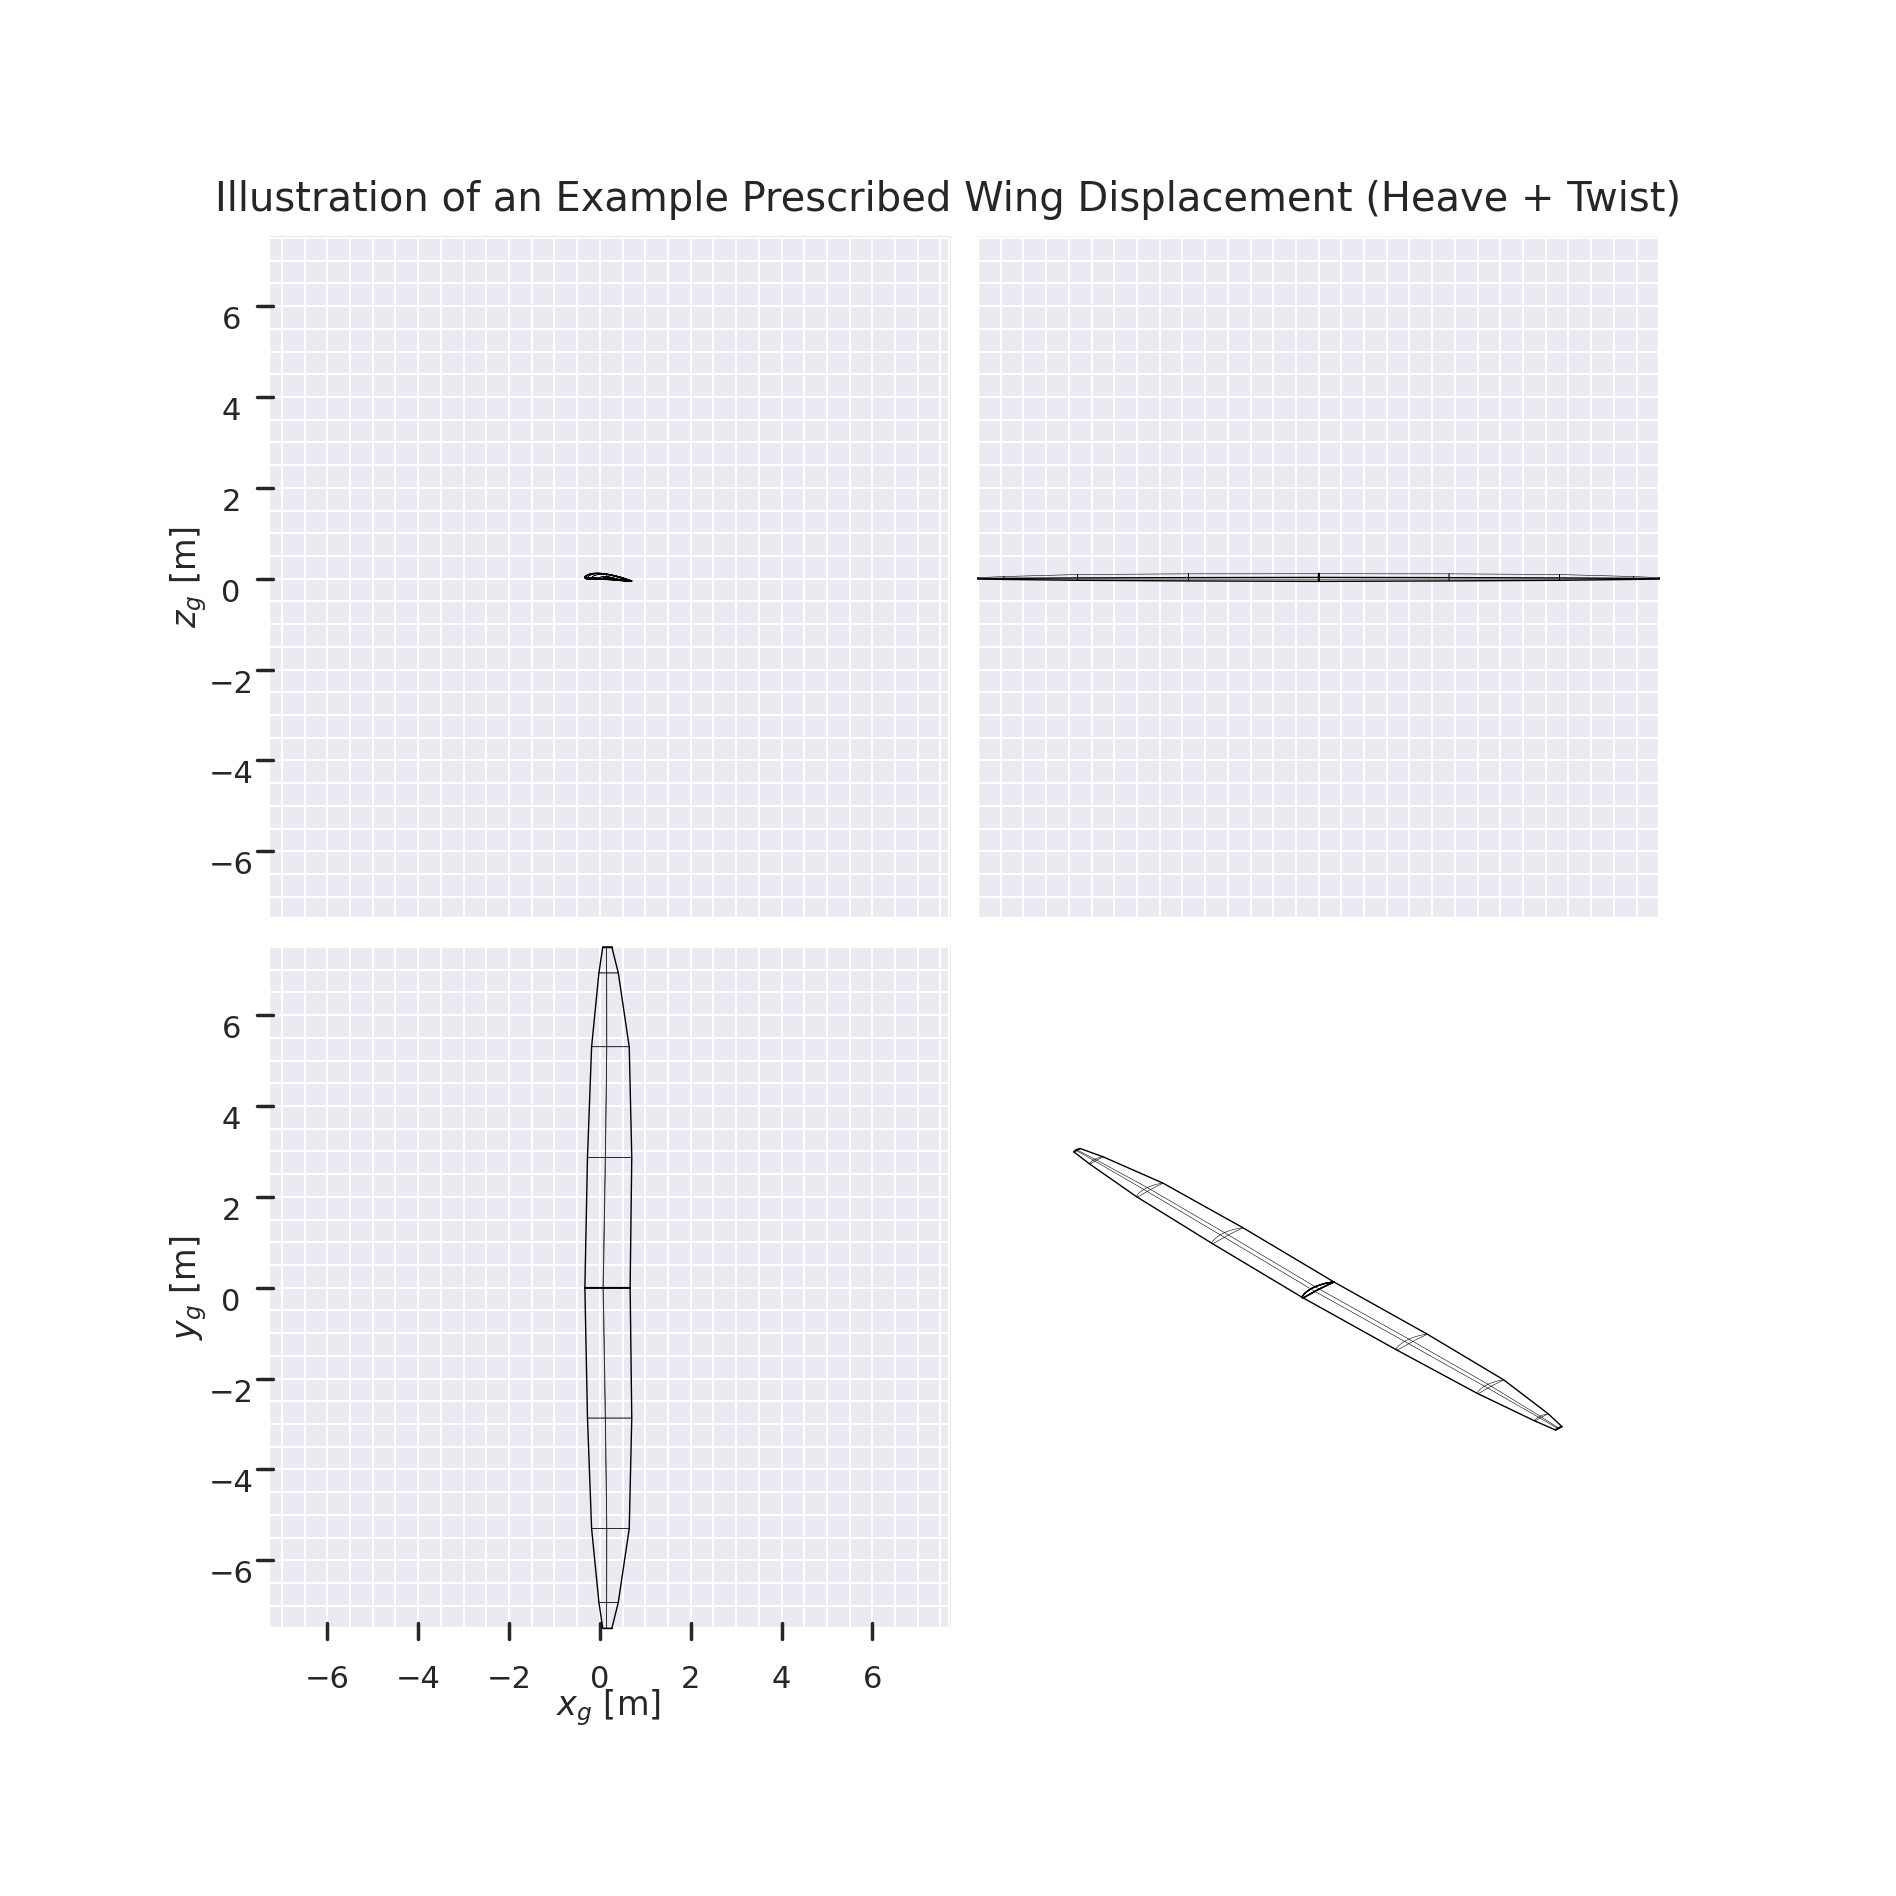

In [12]:
span = 15

# Define reference grid (fixed, high resolution)
ys_over_half_span_ei = np.sin(np.linspace(0, 1, 5) * np.pi / 2)
EI_func = Function(ys_over_half_span_ei, np.array([9.43391251e+05, 5.86626012e+05, 3.03176197e+05, 1.10509509e+05, 5.92279737e+04]))
GJ_func = Function(ys_over_half_span_ei, np.array([731433.62037139, 362923.35599639, 178770.9402976, 62281.35421644, 32651.31597165]))

chord_fun = ChordFunction(
    chord_ctrl_pos=0.75,
    chord_weight_ctrl=2,
    chord_root=1,
    chord_tip=0.2,  # sqrt(0.1)
)

twist_fun = TwistFunction(
    twist_root=5,
    twist_tip=3,
    twist_mean_pos=0.5
)

# For current N, interpolate to ys_over_half_span
ys_over_half_span = np.sin(np.linspace(0, 1, 5) * np.pi / 2)  # Or vary N here
chords = chord_fun.evaluate(ys_over_half_span)
twists = twist_fun.evaluate(ys_over_half_span)
offsets = (np.tan(np.radians(1))) * ys_over_half_span * (span / 2) - chords * 0.33

wing = make_wing(
    span=span,
    ys_over_half_span=ys_over_half_span,
    chords=chords,
    twists=twists,
    offsets=offsets,
    color="black",
)


preset_view_angles = np.array([
    ["XZ", "-YZ"],
    ["XY", "left_isometric"]
], dtype="O")

fig, axs = p.figure3d(
    nrows=preset_view_angles.shape[0],
    ncols=preset_view_angles.shape[1],
    figsize=(8, 8),
)

for i in range(axs.shape[0]):
    for j in range(axs.shape[1]):
        ax = axs[i, j]
        preset_view = preset_view_angles[i, j]

        for w in [wing]:
            w.draw_wireframe(
                ax=ax,
                set_axis_visibility=False if 'isometric' in preset_view else None,
                show=False,
            )

        p.set_preset_3d_view_angle(preset_view)

        xres = np.diff(ax.get_xticks())[0]
        yres = np.diff(ax.get_yticks())[0]
        zres = np.diff(ax.get_zticks())[0]

        p.set_ticks(
            xres, xres / 4,
            yres, yres / 4,
            zres, zres / 4,
        )

        ax.xaxis.set_tick_params(color='white', which='minor')
        ax.yaxis.set_tick_params(color='white', which='minor')
        ax.zaxis.set_tick_params(color='white', which='minor')

        if preset_view == 'XY' or preset_view == '-XY':
            ax.set_zticks([])
        if preset_view == 'XZ' or preset_view == '-XZ':
            ax.set_yticks([])
        if preset_view == 'YZ' or preset_view == '-YZ':
            ax.set_xticks([])

axs[1, 0].set_xlabel("$x_g$ [m]")
axs[1, 0].set_ylabel("$y_g$ [m]")
axs[0, 0].set_zlabel("$z_g$ [m]")
axs[0, 0].set_xticklabels([])
axs[0, 1].set_yticklabels([])
axs[0, 1].set_zticklabels([])

plt.subplots_adjust(
    left=-0.08,
    right=1.08,
    bottom=-0.08,
    top=1.08,
    wspace=-0.38,
    hspace=-0.38,
)
plt.suptitle("Illustration of an Example Prescribed Wing Displacement (Heave + Twist)")

p.show_plot(tight_layout=False)

## Roadmap for the experiments
1. Define geometry and baseline material properties.
2. Solve aeroelastic equilibrium using the shear-based bending formulation.
3. Solve aeroelastic equilibrium using the direct moment formulation.
4. Compare physical interpretation and numerical behavior.
5. Run convergence studies over panel/section resolutions.
6. Visualize force/moment-arm geometry for debugging and validation.

Tip: the convergence sections can be computationally expensive; run them after validating the baseline case.

### Formulation A: shear-based bending equation
In this section, bending is modeled as
$$\frac{d}{dy}(EI\,u'')=-V$$
with derivatives discretized on section locations.

Because loads are aggregated per interval, this introduces a lever-arm approximation (effectively using interval-averaged force locations). This can bias bending moments when force density varies strongly within an interval (e.g., due to taper).

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:      145
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:       55

Total number of variables............................:       25
                     variables with only lower bounds:        0
                variables with lower and upper bounds:        0
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  0.0000000e+00 2.05e+04 0.00e+00   0.0 0.00e+00    -  0.00e+00 0.00e+00 

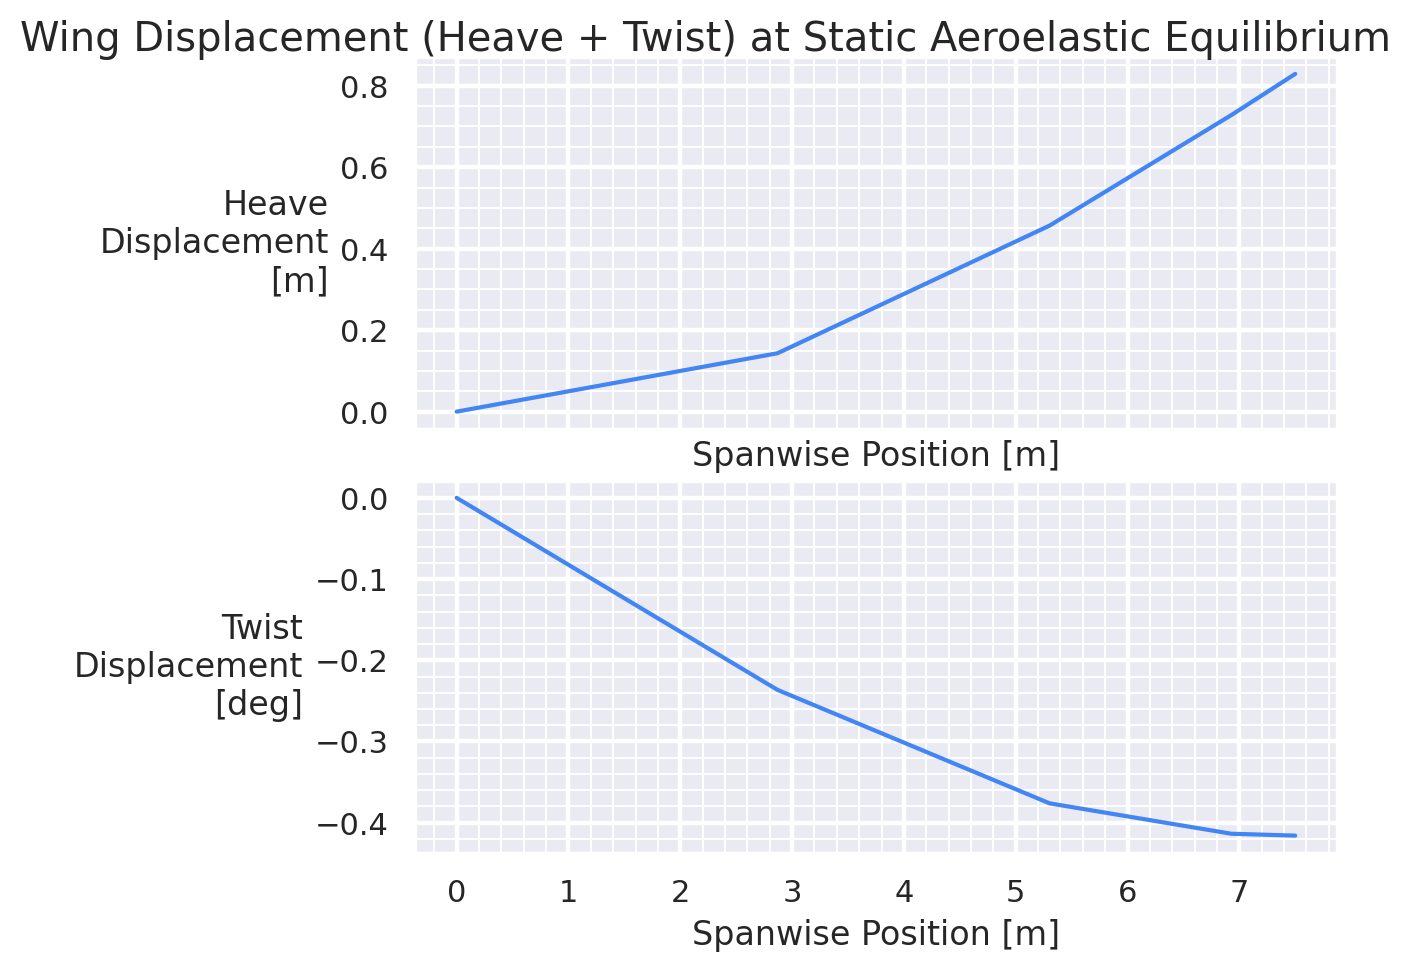

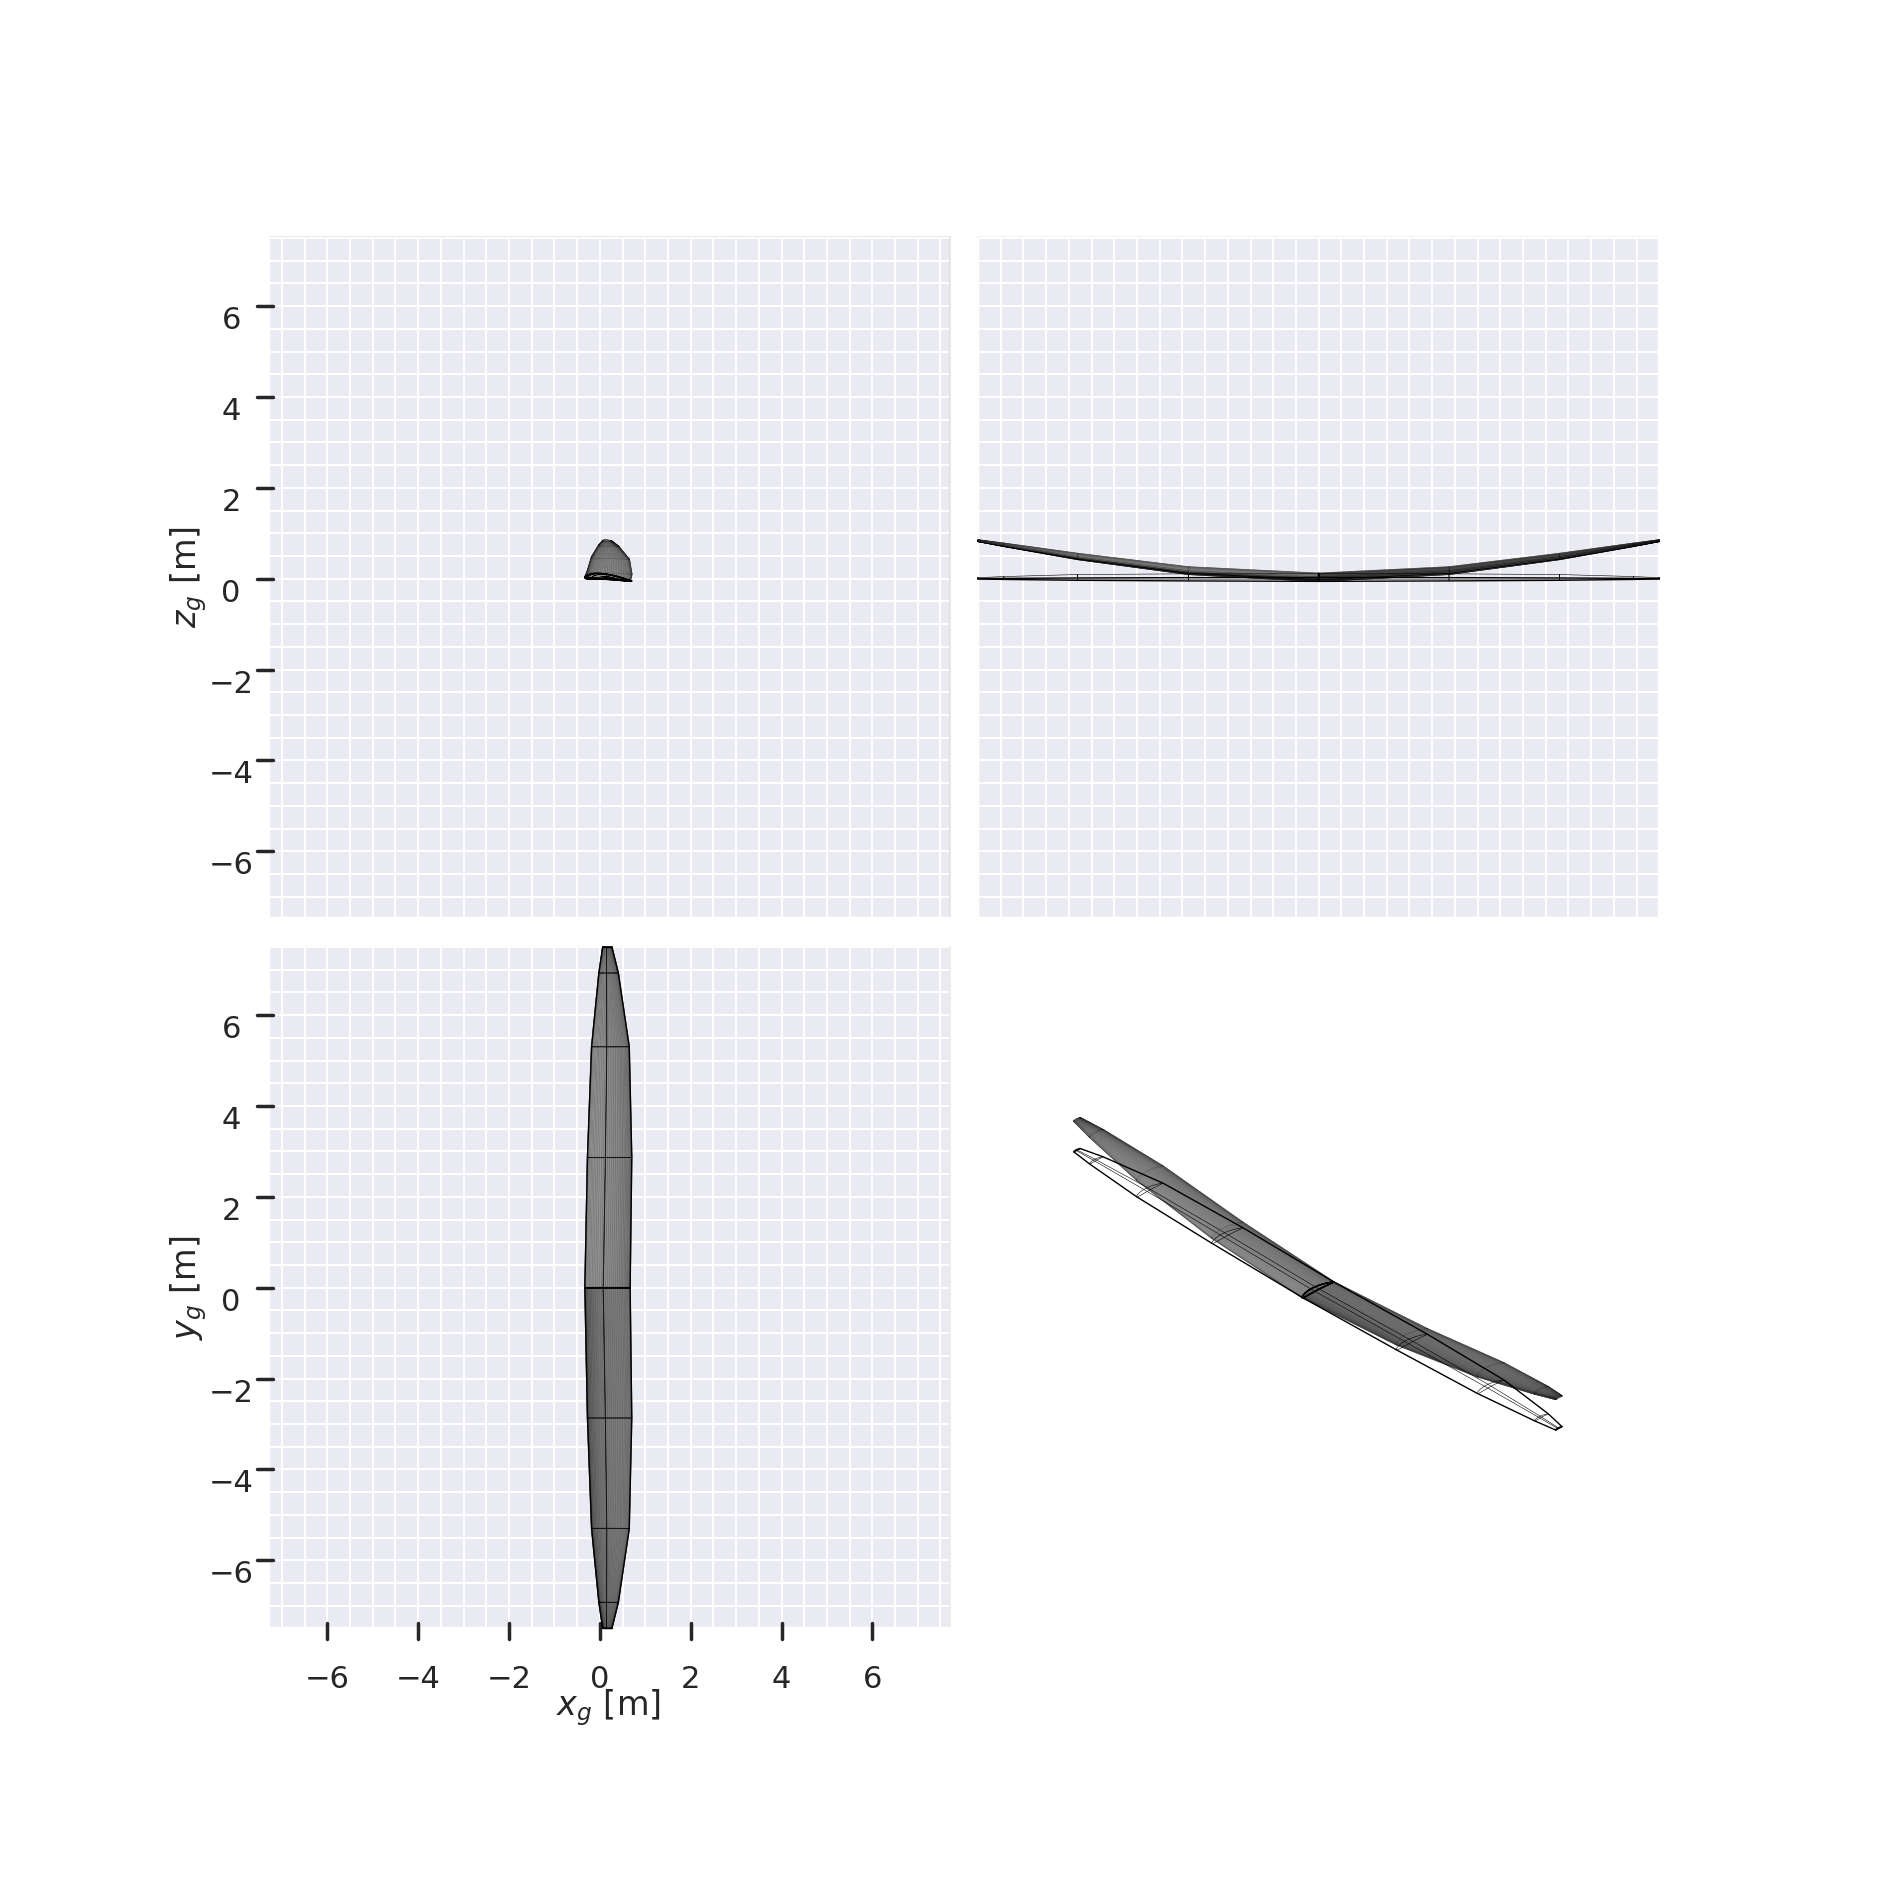

max_bending_moment: 37586.16059605574
max_torsion_moment: -1123.0152811918317


<Figure size 1280x960 with 0 Axes>

In [13]:
EI = EI_func.evaluate(ys_over_half_span)
GJ = GJ_func.evaluate(ys_over_half_span)

solution = solve_static_aeroelastic_equilibrium(
    make_wing_fn=make_wing,
    span=span,
    ys_over_half_span=ys_over_half_span,
    chords=chords,
    twists=twists,
    offsets=offsets,
    EI=EI,
    GJ=GJ,
    velocity=50,
    alpha=0,
    chordwise_resolution=5,
    spanwise_resolution=5,
    bending_model="shear",
)

sol = solution["sol"]
wing = solution["wing"]
vlm = solution["vlm"]
u = solution["u"]
theta = solution["theta"]
du = solution["du"]
ddu = solution["ddu"]
dtheta = solution["dtheta"]
ys = solution["ys"]

### Display output
fig, ax = plt.subplots(2, 1, sharex=True)
ax[0].plot(ys, sol(u), label="Heave")
ax[0].set_ylabel("Heave Displacement [m]")
ax[1].plot(ys, np.degrees(sol(theta)), label="Twist")
ax[1].set_ylabel("Twist Displacement [deg]")
p.show_plot(
    title="Wing Displacement (Heave + Twist) at Static Aeroelastic Equilibrium",
    xlabel="Spanwise Position [m]",
    legend=False,
)

heave_displacements = sol(u)
twist_displacements = sol(theta)*180/np.pi

wing_deformed = make_wing(
    span=span,
    ys_over_half_span=ys_over_half_span,
    chords=chords,
    twists=twists,
    offsets=offsets,
    heave_displacements=heave_displacements,
    twist_displacements=twist_displacements,
)
wing_deformed.color = "C0"
axs = wing_deformed.draw_three_view(show=False)
make_wing(
    span=span,
    ys_over_half_span=ys_over_half_span,
    chords=chords,
    twists=twists,
    offsets=offsets,
).draw_three_view(axs=axs, style="wireframe")
plt.suptitle("Wing Displacement (Heave + Twist) at Static Aeroelastic Equilibrium")

load_summary = summarize_internal_loads(solution)
print(f"max_bending_moment: {load_summary['max_bending_moment']}")
print(f"max_torsion_moment: {load_summary['max_torsion_moment']}")

### Formulation B: direct moment-based bending equation
Here, bending is modeled directly as
$$EI\,u'' = M$$
where $M$ is computed from panel forces and their individual spanwise lever arms relative to each structural section.

This removes the interval-average lever-arm assumption and gives a more physically faithful moment reconstruction.

This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:      141
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:       55

Total number of variables............................:       25
                     variables with only lower bounds:        0
                variables with lower and upper bounds:        0
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  0.0000000e+00 2.59e+04 0.00e+00   0.0 0.00e+00    -  0.00e+00 0.00e+00 

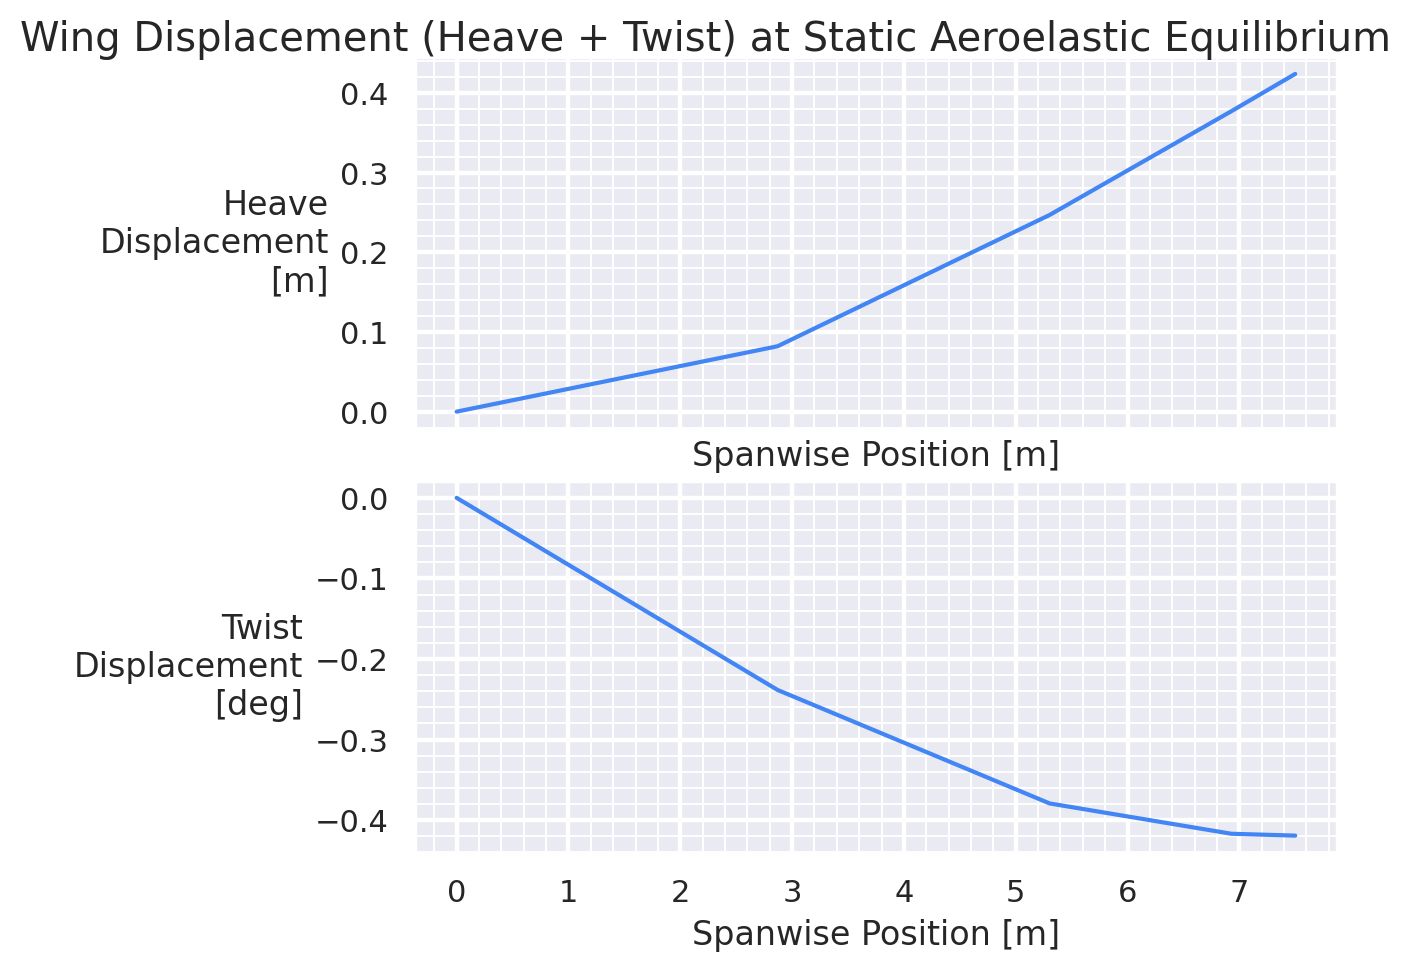

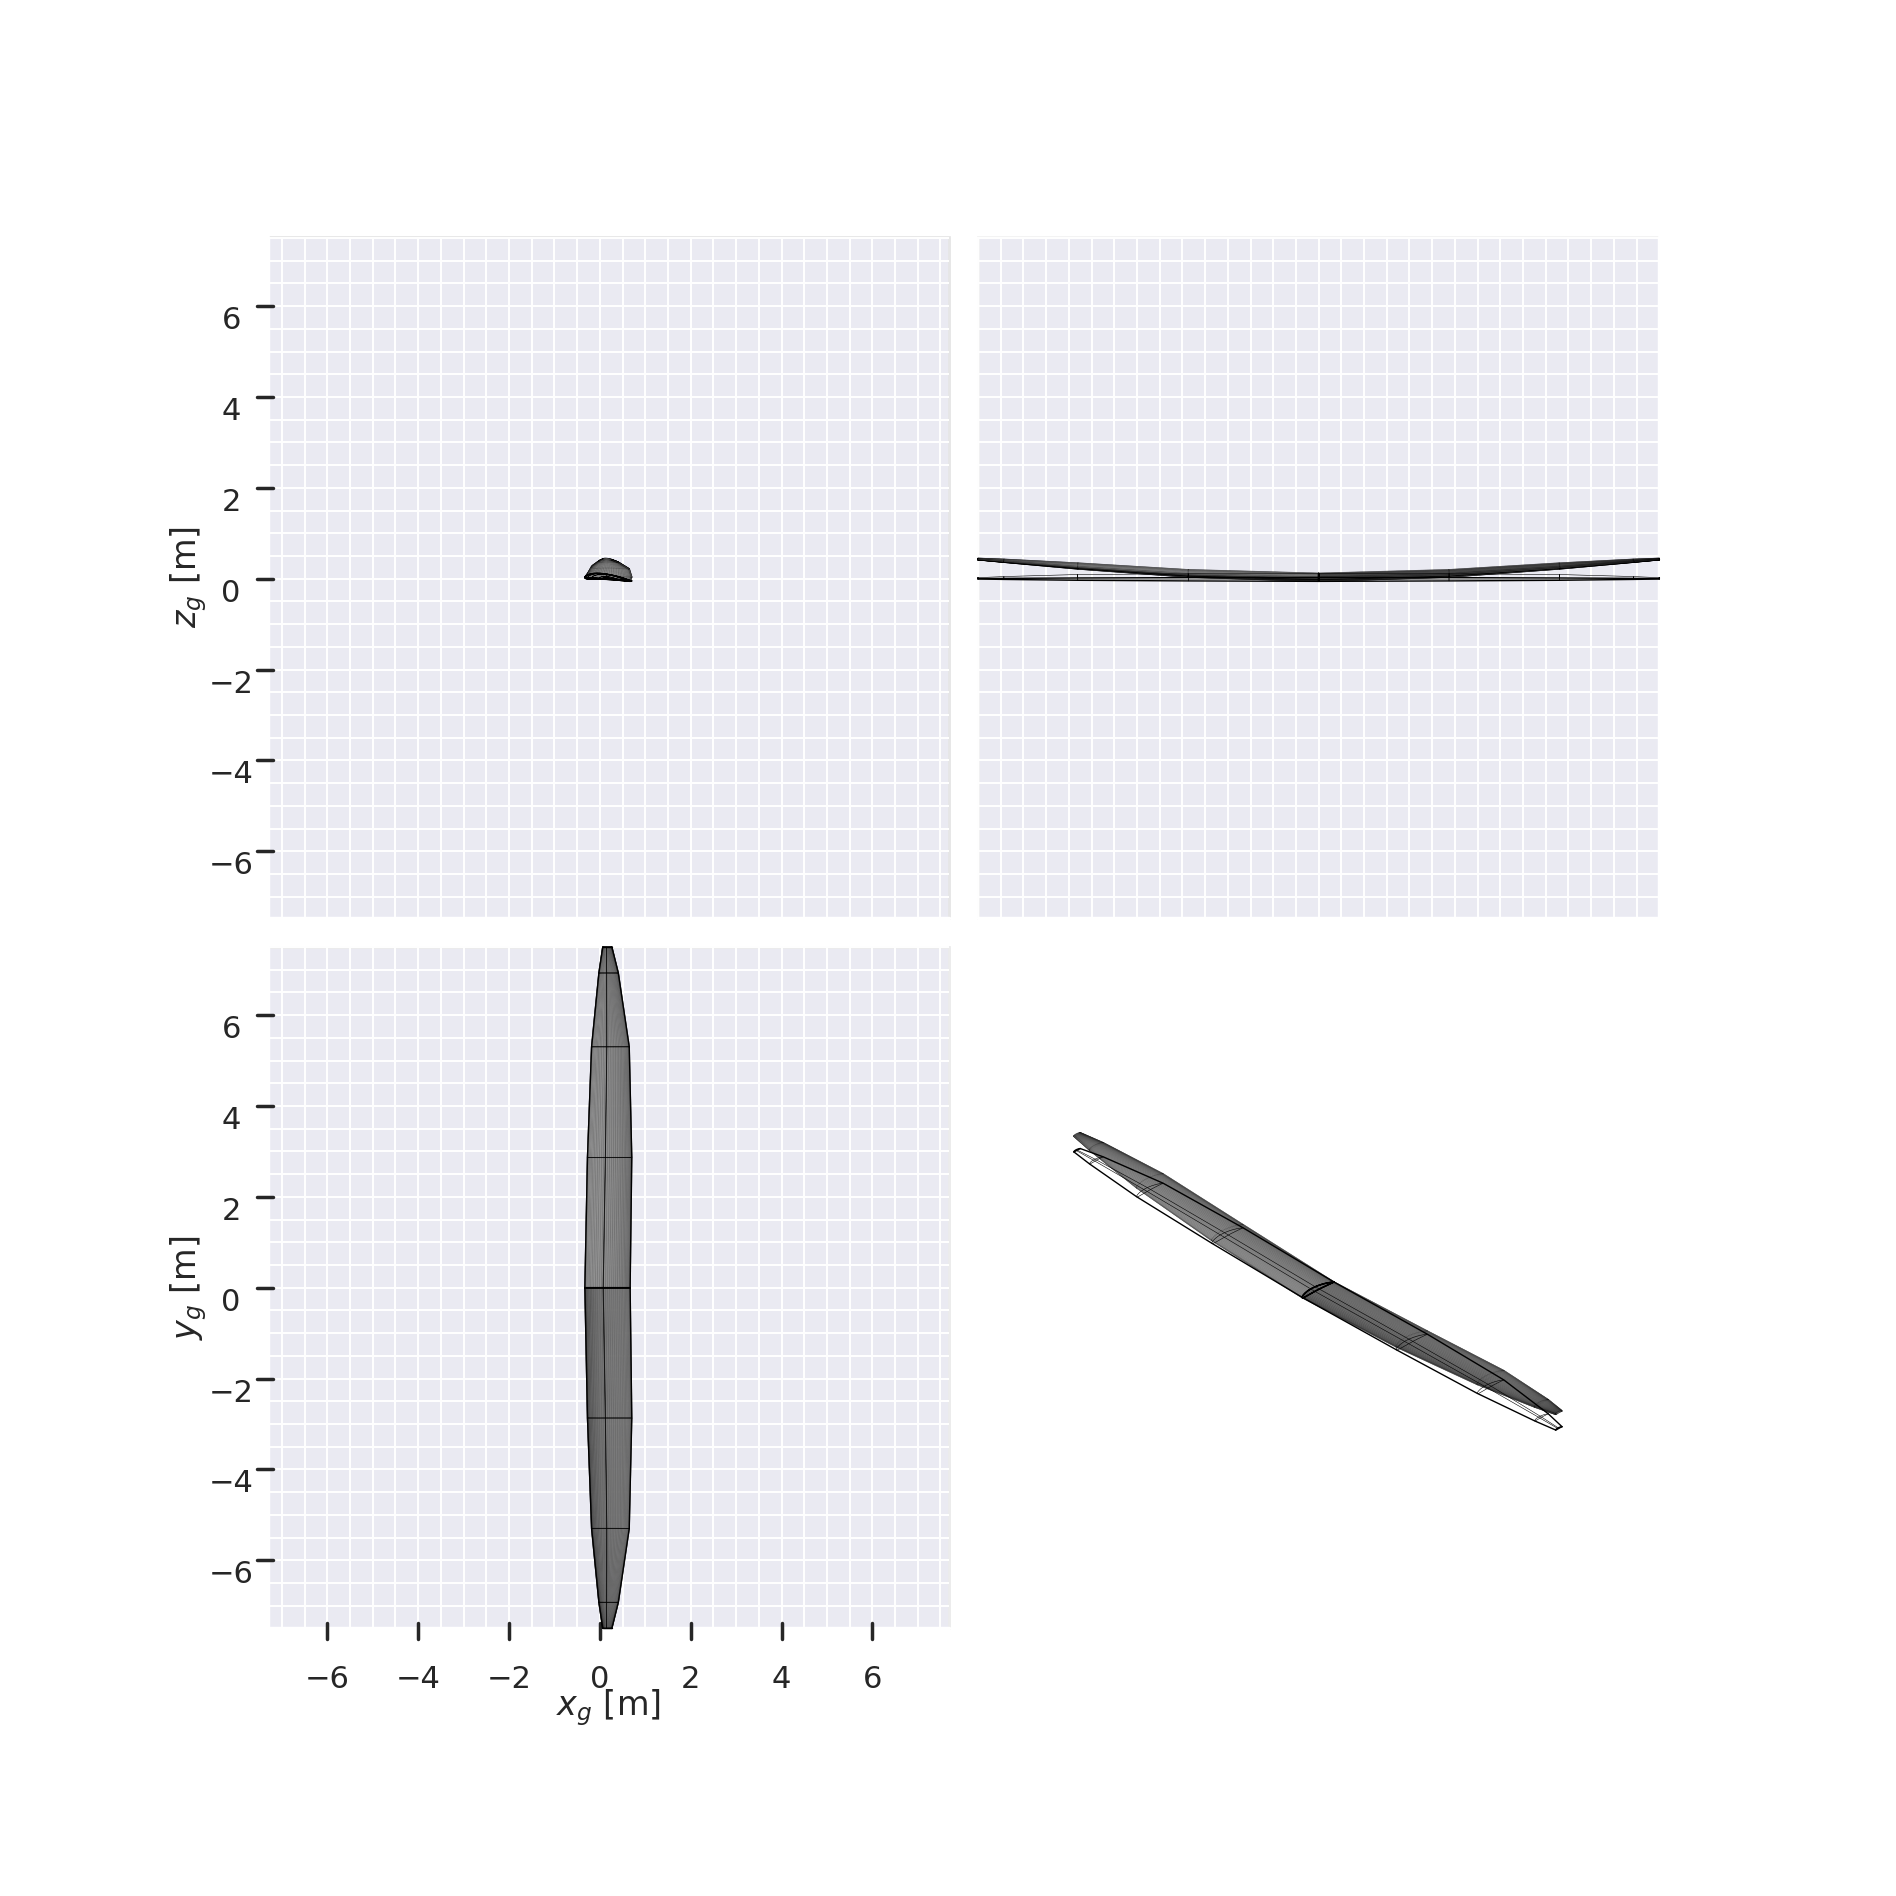

max_bending_moment: 25070.796447309225
max_torsion_moment: -1131.070489767025


<Figure size 1280x960 with 0 Axes>

In [14]:
EI = EI_func.evaluate(ys_over_half_span)
GJ = GJ_func.evaluate(ys_over_half_span)

solution = solve_static_aeroelastic_equilibrium(
    make_wing_fn=make_wing,
    span=span,
    ys_over_half_span=ys_over_half_span,
    chords=chords,
    twists=twists,
    offsets=offsets,
    EI=EI,
    GJ=GJ,
    velocity=50,
    alpha=0,
    chordwise_resolution=5,
    spanwise_resolution=5,
    bending_model="moment",
)

sol = solution["sol"]
wing = solution["wing"]
vlm = solution["vlm"]
u = solution["u"]
theta = solution["theta"]
du = solution["du"]
ddu = solution["ddu"]
dtheta = solution["dtheta"]
ys = solution["ys"]


### Display output
fig, ax = plt.subplots(2, 1, sharex=True)
ax[0].plot(ys, sol(u), label="Heave")
ax[0].set_ylabel("Heave Displacement [m]")
ax[1].plot(ys, np.degrees(sol(theta)), label="Twist")
ax[1].set_ylabel("Twist Displacement [deg]")
p.show_plot(
    title="Wing Displacement (Heave + Twist) at Static Aeroelastic Equilibrium",
    xlabel="Spanwise Position [m]",
    legend=False,
)

heave_displacements = sol(u)
twist_displacements = sol(theta)*180/np.pi

wing_deformed = make_wing(
    span=span,
    ys_over_half_span=ys_over_half_span,
    chords=chords,
    twists=twists,
    offsets=offsets,
    heave_displacements=heave_displacements,
    twist_displacements=twist_displacements,
)
wing_deformed.color = "C0"
axs = wing_deformed.draw_three_view(show=False)
make_wing(
    span=span,
    ys_over_half_span=ys_over_half_span,
    chords=chords,
    twists=twists,
    offsets=offsets,
).draw_three_view(axs=axs, style="wireframe")
plt.suptitle("Wing Displacement (Heave + Twist) at Static Aeroelastic Equilibrium")

load_summary = summarize_internal_loads(solution)
print(f"max_bending_moment: {load_summary['max_bending_moment']}")
print(f"max_torsion_moment: {load_summary['max_torsion_moment']}")

### Interpretation of the difference
The shear-based discretization tends to overestimate bending moments in this setup because interval-mean lever arms are larger than the effective lever arm of the true load distribution (which is root-biased for tapered wings).

> Practical takeaway: for coarse structural grids, direct panel-based moment accumulation can produce more reliable bending trends.

## Diagnostic visualization of load paths
This section adds an engineering sanity check of the deformed configuration by visualizing:
- panel force vectors from VLM,
- inferred shear-center locations,
- selected moment-arm geometry used in torque reconstruction.

Use this to confirm sign conventions and qualitative force-flow before interpreting convergence trends.


Section 0: shear_center at (0.0033, 0.0000, 0.0000)
  Panel 0: r=[-0.3213, 0.0546, 0.0322], F=[-2.6630, -0.1665, 8.2903], moment=2.577696
  Panel 1: r=[-0.2646, 0.0543, 0.0416], F=[-2.6029, -0.4544, 18.8881], moment=4.889881
  Panel 2: r=[-0.1414, 0.0540, 0.0529], F=[-1.7075, -0.8248, 31.2637], moment=4.329961
  Total torque for section 0: -1093.934534

Section 1: shear_center at (0.0534, 2.8701, 0.0820)
  Panel 64: r=[-0.3139, 0.0462, 0.0276], F=[-1.3926, -0.2592, 4.7968], moment=1.467347
  Panel 65: r=[-0.2588, 0.0456, 0.0377], F=[-1.9517, -0.7701, 12.9747], moment=3.284622
  Panel 66: r=[-0.1389, 0.0449, 0.0508], F=[-1.6319, -1.4444, 23.1516], moment=3.131985
  Total torque for section 1: -469.213821

Section 2: shear_center at (0.0953, 5.3033, 0.2468)
  Panel 128: r=[-0.2652, 0.0308, 0.0195], F=[-0.3346, -0.0687, 1.3601], moment=0.354222
  Panel 129: r=[-0.2189, 0.0301, 0.0287], F=[-0.8908, -0.3317, 5.6503], moment=1.211301
  Panel 130: r=[-0.1178, 0.0292, 0.0411], F=[-0.9377, -0.

/home/lorenzomiele/.cache/devcontainers-tmp/ipykernel_25377/3624978726.py:148: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  plotter.show()


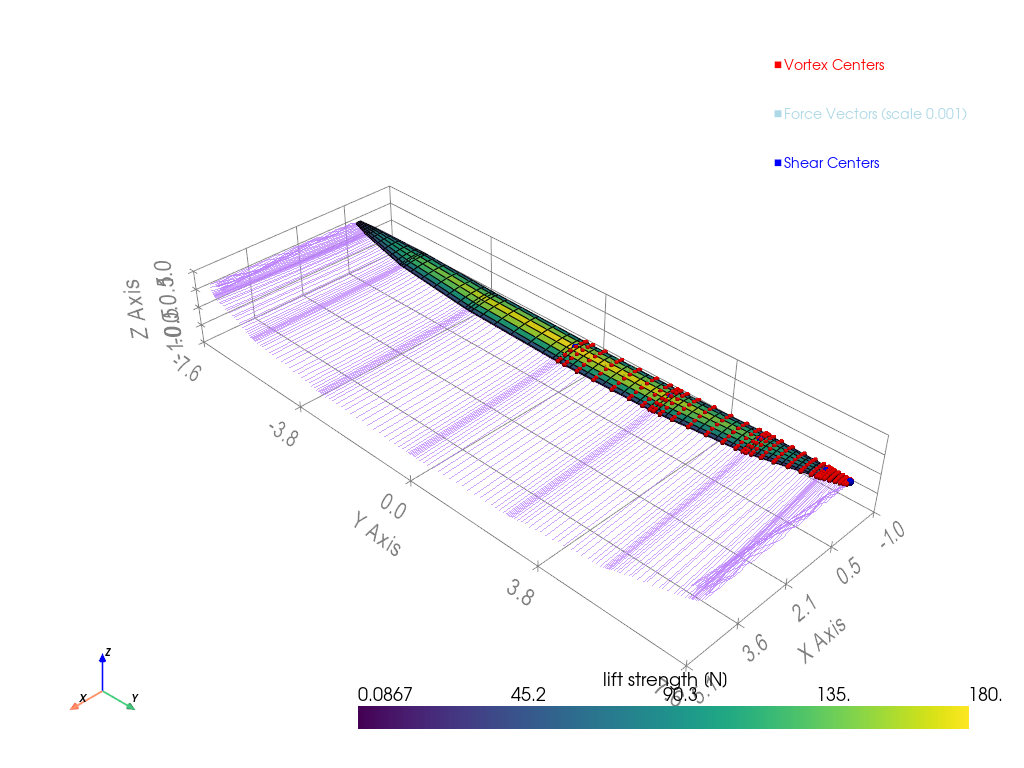

In [15]:
vlm = asb.VortexLatticeMethod(
    airplane=asb.Airplane(
        name="Aerostructures Test",
        xyz_ref=[0, 0, 0],
        wings=[wing_deformed],
    ),
    op_point=asb.OperatingPoint(
        velocity=50,
        alpha=0,
    ),
    chordwise_resolution= 8,
    spanwise_resolution=8,
)

vlm.run()

num_intervals = (len(ys) - 1)
num_panels_per_interval = vlm.spanwise_resolution * vlm.chordwise_resolution

"""Calculate torques using numpy for debugging/verification purposes.

Args:
    vlm: VortexLatticeMethod object with solved results
    num_intervals: Number of structural sections
    num_panels_per_interval: Panels per structural section
    offsets: Array of x-offsets for shear centers
    ys: Array of spanwise positions

Returns:
    section_torques: Torques at each section from outboard forces
"""

# Get data from VLM
num_panels = num_intervals * num_panels_per_interval
vortex_centers = vlm.vortex_centers[:num_panels, :]  # Shape: (num_panels, 3)
forces = vlm.forces_geometry[:num_panels, :]         # Shape: (num_panels, 3)

section_torques = []
r_vectors_all = []
for sect_idx in range(num_intervals):
    # Get shear center position for this section
    shear_centers_3d = np.array([[offsets[i]+chords[i]/3, ys[i], heave_displacements[i]] for i in range(len(offsets))])
    
    # Calculate cumulative torque from all forces outboard of this section
    cumulative_torque = 0.0
    start_idx = sect_idx * num_panels_per_interval
    
    print(f"\nSection {sect_idx}: shear_center at ({shear_centers_3d[sect_idx, 0]:.4f}, {ys[sect_idx]:.4f}, {heave_displacements[sect_idx]:.4f})")
    r_vectors = []
    # Sum torques from this section to the tip (all outboard forces)
    for j in range(start_idx, num_panels):
        # Position vector from shear center to vortex center
        r_vector = vortex_centers[j, :] - shear_centers_3d[sect_idx, :]
        r_vectors.append((shear_centers_3d[sect_idx, :], vortex_centers[j, :]))
        # Cross product: r × F (only take y-component for torsion about span)
        # (r × F)_y = r_z * F_x - r_x * F_z
        moment = r_vector[2] * forces[j, 0] - r_vector[0] * forces[j, 2]
        cumulative_torque += moment
        
        if j < start_idx + 3:  # Print first few for debugging
            print(f"  Panel {j}: r=[{r_vector[0]:.4f}, {r_vector[1]:.4f}, {r_vector[2]:.4f}], "
                    f"F=[{forces[j, 0]:.4f}, {forces[j, 1]:.4f}, {forces[j, 2]:.4f}], "
                    f"moment={moment:.6f}")
    
    section_torques.append(cumulative_torque)
    print(f"  Total torque for section {sect_idx}: {cumulative_torque:.6f}")
    r_vectors_all.append(r_vectors)
# Draw with show=False to get the plotter object
plotter = vlm.draw(show=False, colorbar_label="lift strength [N]", cmap="viridis")
plotter.remove_scalar_bar()

# Get data from VLM
num_panels = num_intervals * num_panels_per_interval
vortex_centers = vlm.vortex_centers[:num_panels, :]  # Shape: (num_panels, 3)
forces = vlm.forces_geometry[:num_panels, :]         # Shape: (num_panels, 3)

# Calculate force magnitudes for consistent coloring
force_magnitudes = np.linalg.norm(forces, axis=1)
min_force = np.min(force_magnitudes)
max_force = np.max(force_magnitudes)
"""
# Create the plotter
plotter = pv.Plotter()
plotter.title = "Forces and Moment Arms"
plotter.add_axes()
plotter.show_grid(color="gray")
"""
# Add vortex center points colored by force magnitude
vortex_centers_cloud = pv.PolyData(vortex_centers)
plotter.add_mesh(
    vortex_centers_cloud, 
    point_size=5, 
    render_points_as_spheres=True,
    label='Vortex Centers',
    color="red"
)

# Add force vectors with consistent coloring
force_scale = 0.001
arrows = pv.PolyData(vortex_centers)
arrows["force_vectors"] = forces
arrows["lift strength [N]"] = force_magnitudes

arrow_glyphs = arrows.glyph(
    orient="force_vectors",
    scale="force_vectors",
    factor=force_scale,
    geom=pv.Arrow()
)

plotter.add_mesh(
    arrow_glyphs,
    scalars=f"lift strength [N]",
    cmap='viridis',
    label=f"Force Vectors (scale {force_scale})",
    clim=[min_force, max_force]
)

# Add shear centers
shear_centers_cloud = pv.PolyData(shear_centers_3d)
plotter.add_mesh(
    shear_centers_cloud, 
    color='blue', 
    point_size=8, 
    render_points_as_spheres=True,
    label='Shear Centers'
)
"""
# Add moment arm lines for first section
section_idx = 0
r_vectors = r_vectors_all[section_idx]
for i in range(len(r_vectors)):
    line = pv.Line(r_vectors[i][0], r_vectors[i][1])
    plotter.add_mesh(
        line,
        color='orange',
        opacity=1,
        line_width=2.5
    )
"""

# Add legend and show
plotter.add_legend(
    size=(0.2, 0.2),
    loc='upper right',
    face='rectangle'
)
plotter.show()

## Stability-derivative spot check
This short cell runs a higher-angle-of-attack VLM call with stability derivatives to sanity-check the deformed configuration in a nearby operating condition.

It is not a full stability map; it is a quick consistency check before running large design studies.

In [16]:
t1 = time.time()
vlm = asb.VortexLatticeMethod(
    airplane=asb.Airplane(
        name="Aerostructures Test",
        xyz_ref=[0, 0, 0],
        wings=[wing_deformed],
    ),
    op_point=asb.OperatingPoint(
        velocity=50,
        alpha=5,
    ),
    chordwise_resolution= 8,
    spanwise_resolution=8,
)

aero = vlm.run_with_stability_derivatives(alpha=True, beta=False, p=False, q=False, r=False)
t2 = time.time()
print(f"VLM run time: {t2 - t1:.2f} seconds")
print(aero)

VLM run time: 0.07 seconds
{'F_g': array([-1.65520381e+03,  1.55133718e-13,  2.58964088e+04]), 'F_b': (np.float64(1655.203814438811), np.float64(1.551337183713919e-13), np.float64(-25896.408844315298)), 'F_w': (np.float64(-608.1154831181468), np.float64(1.551337183713919e-13), np.float64(-25942.125708169257)), 'M_g': array([-4.63731276e-11, -2.38995918e+03,  4.56079619e-13]), 'M_b': (np.float64(4.637312756017309e-11), np.float64(-2389.9591810822258), np.float64(-4.560796185160143e-13)), 'M_w': (np.float64(4.61569138514728e-11), np.float64(-2389.9591810822258), np.float64(-4.496028473912142e-12)), 'L': np.float64(25942.125708169257), 'D': np.float64(608.1154831181468), 'Y': np.float64(1.551337183713919e-13), 'l_b': np.float64(4.637312756017309e-11), 'm_b': np.float64(-2389.9591810822258), 'n_b': np.float64(-4.560796185160143e-13), 'CL': np.float64(1.3557660221379482), 'CD': np.float64(0.03178083087030762), 'CY': np.float64(8.107470706982917e-18), 'Cl': np.float64(1.612743703287011e-16),

## Convergence sweeps setup
The next cells run two numerical studies using shared helper functions moved to `DataGenerator.utils.notebooks_utils` and imported via `DataGenerator.utils`:
1. **Aerodynamic-panel sweep** (fixed structural sections, varying chordwise/spanwise VLM resolution).
2. **Structural-section sweep** (varying structural sections with controlled panel budget).

These sweeps are the main evidence for discretization robustness of the chosen aeroelastic formulation.

In [17]:
span = 15
ys_over_half_span = np.sin(np.linspace(0, 1, 5) * np.pi / 2)
EI_func = Function(
    ys_over_half_span,
    np.array([9.43391251e+05, 5.86626012e+05, 3.03176197e+05, 1.10509509e+05, 5.92279737e+04]),
)
GJ_func = Function(
    ys_over_half_span,
    np.array([731433.62037139, 362923.35599639, 178770.9402976, 62281.35421644, 32651.31597165]),
)

chord_fun = ChordFunction(
    chord_ctrl_pos=0.75,
    chord_weight_ctrl=2,
    chord_root=1,
    chord_tip=0.2,  # sqrt(0.1)
)

twist_fun = TwistFunction(
    twist_root=5,
    twist_tip=3,
    twist_mean_pos=0.5
)

# Define resolution ranges to test
chord_resolutions = np.arange(1, 10, 2)  # [1, 3, 5, 7, 9]
span_resolutions = np.arange(1, 10, 2)   # [1, 3, 5, 7, 9]

panel_sweep_results = run_panel_resolution_sweep(
    span=span,
    ys_over_half_span=ys_over_half_span,
    chord_fun=chord_fun,
    twist_fun=twist_fun,
    EI_func=EI_func,
    GJ_func=GJ_func,
    chord_resolutions=chord_resolutions,
    span_resolutions=span_resolutions,
    bending_model="moment",
)

tip_deflection = [r["tip_deflection"] for r in panel_sweep_results]
max_torsion = [r["max_torsion"] for r in panel_sweep_results]
panels_per_half_span = [r["num_panels"] for r in panel_sweep_results]
chordwise_resolutions = [r["chordwise_resolution"] for r in panel_sweep_results]
spanwise_resolutions = [r["spanwise_resolution"] for r in panel_sweep_results]

print(f"Completed {len(tip_deflection)} combinations")

Running for chordwise resolution: 1, spanwise resolution: 1
This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:      141
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:       55

Total number of variables............................:       25
                     variables with only lower bounds:        0
                variables with lower and upper bounds:        0
                     variables with only upper bounds:        0
Total number of equality constraints.................:       25
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  0.0000000e+

### Convergence study 1: aerodynamic panel resolution
This plot evaluates convergence of tip deflection and maximum twist as chordwise/spanwise VLM resolution changes, while keeping structural section count fixed at 5 (4 intervals).

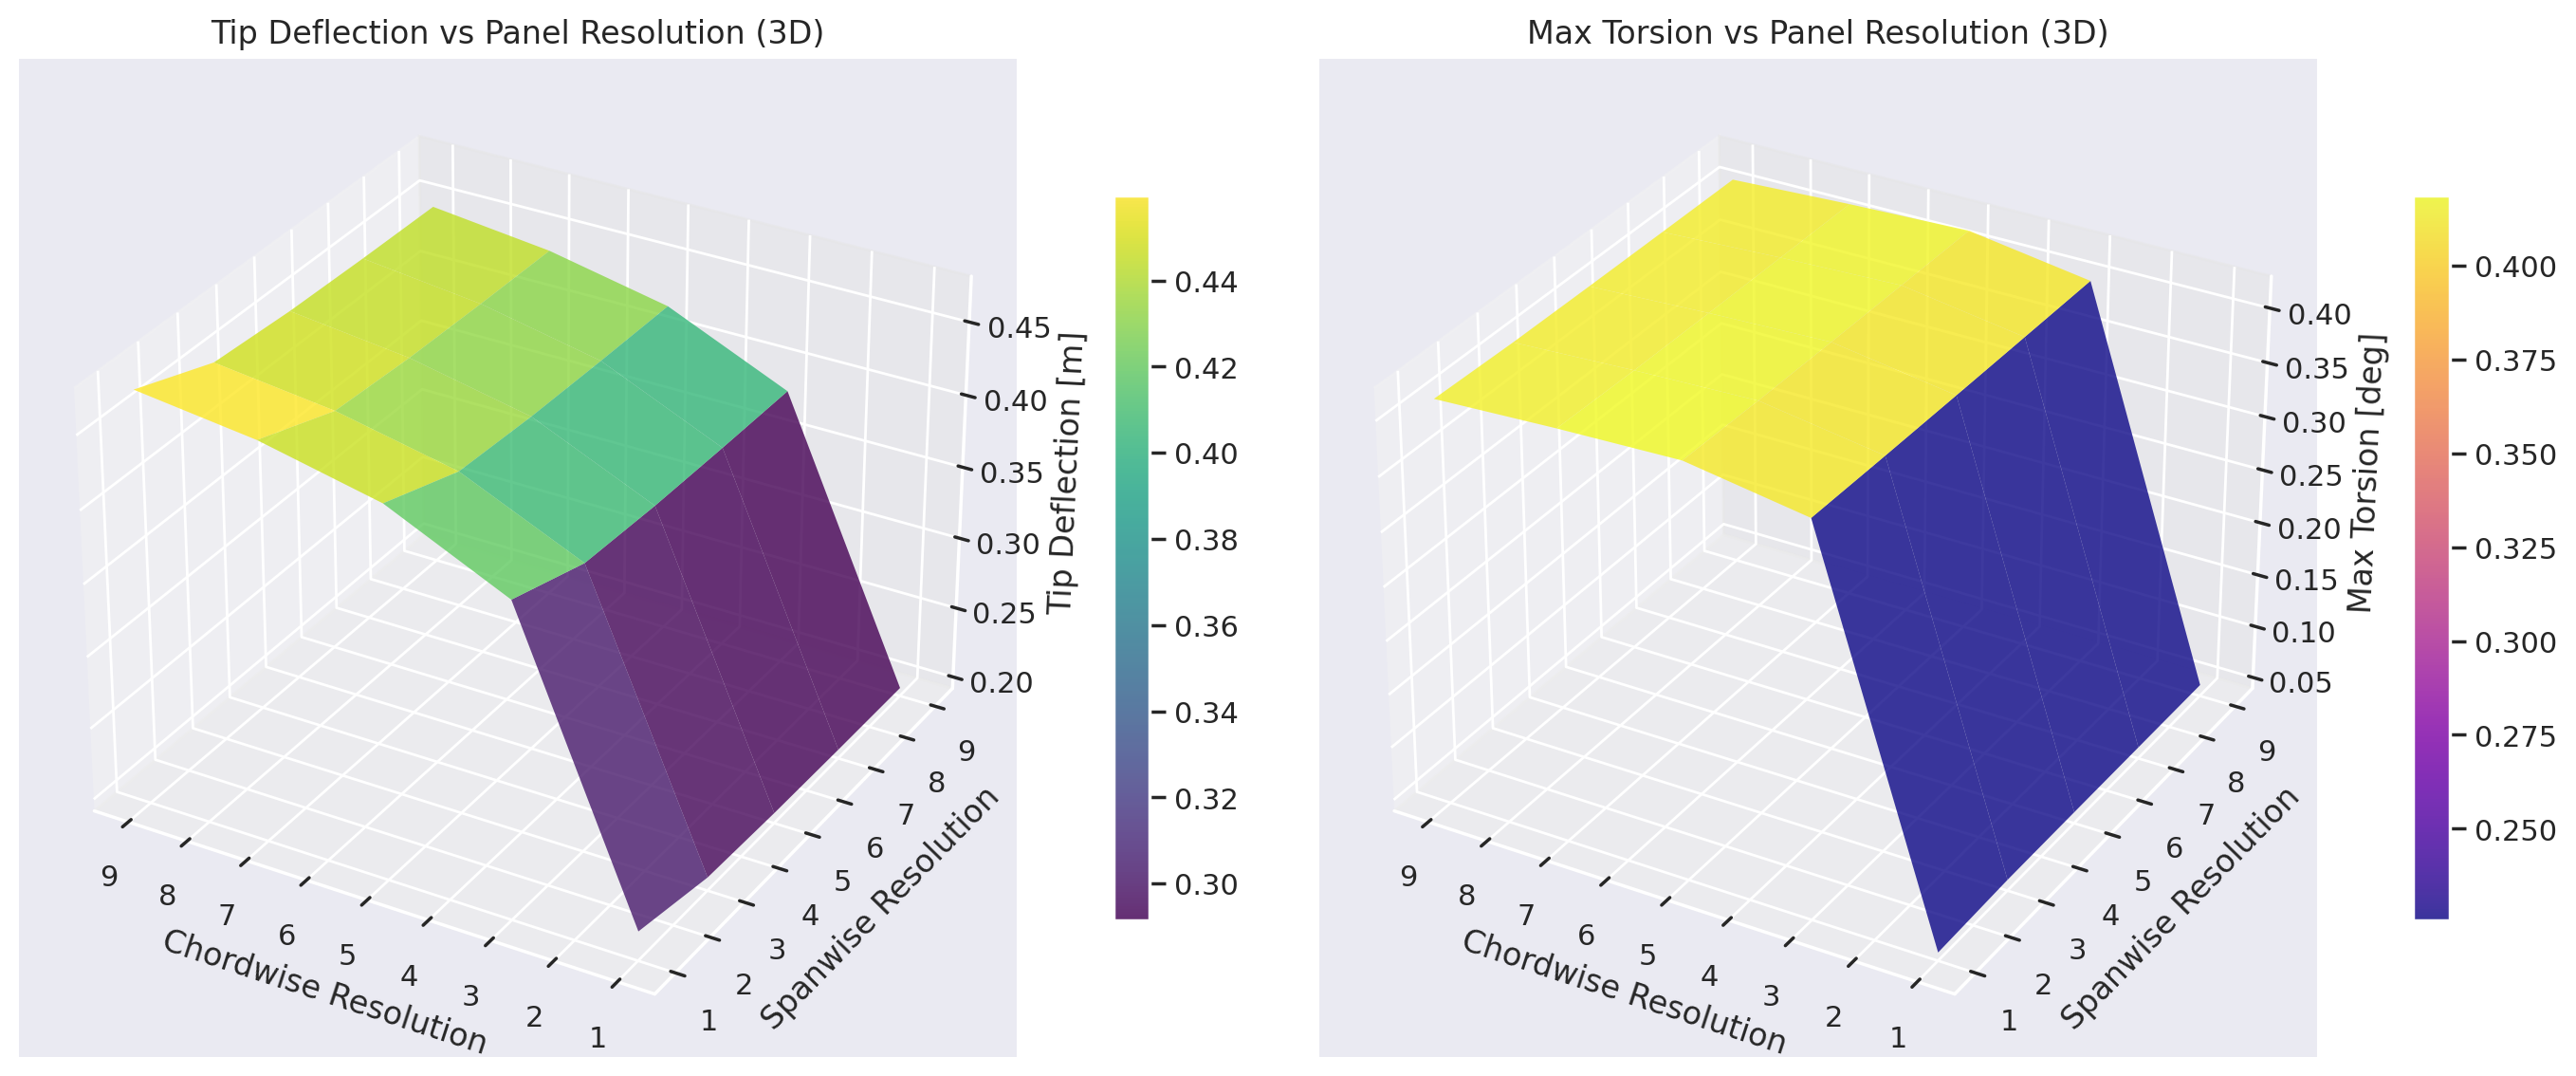

In [18]:
# 3D plots using existing data with flipped chordwise axis
from mpl_toolkits.mplot3d import Axes3D

# Convert lists to numpy arrays for easier manipulation
chord_res_array = np.array(chordwise_resolutions)
span_res_array = np.array(spanwise_resolutions)
tip_def_array = np.array(tip_deflection)
twist_def_array = np.array(max_torsion)

# Reshape data into grids for plotting
n_chord = len(chord_resolutions)
n_span = len(span_resolutions)

# Reshape the flattened results back into 2D grids
tip_def_grid = tip_def_array.reshape(n_chord, n_span)
twist_def_grid = twist_def_array.reshape(n_chord, n_span)

# Create meshgrid for 3D plotting
C, S = np.meshgrid(chord_resolutions, span_resolutions, indexing='ij')

# Create 3D plots
fig = plt.figure(figsize=(14, 8))

# Tip Deflection 3D plot
ax1 = fig.add_subplot(121, projection='3d')
surf1 = ax1.plot_surface(C, S, tip_def_grid, cmap='viridis', alpha=0.8, edgecolor='none')
ax1.set_xlabel('Chordwise Resolution')
ax1.set_ylabel('Spanwise Resolution')
ax1.set_zlabel('Tip Deflection [m]')
ax1.set_title('Tip Deflection vs Panel Resolution (3D)')
# Invert the chordwise axis
ax1.invert_xaxis()
fig.colorbar(surf1, ax=ax1, shrink=0.5, pad = 0.075)

# Max Torsion 3D plot
ax2 = fig.add_subplot(122, projection='3d')
surf2 = ax2.plot_surface(C, S, twist_def_grid, cmap='plasma', alpha=0.8, edgecolor='none')
ax2.set_xlabel('Chordwise Resolution')
ax2.set_ylabel('Spanwise Resolution') 
ax2.set_zlabel('Max Torsion [deg]')
ax2.set_title('Max Torsion vs Panel Resolution (3D)')
# Invert the chordwise axis
ax2.invert_xaxis()
fig.colorbar(surf2, ax=ax2, shrink=0.5, pad = 0.075)

plt.tight_layout()
#plt.savefig("aeroelastic_convergence_3D.svg", format="svg")
plt.show()

### Convergence study 2: structural section resolution
Here the total aerodynamic panel budget is kept approximately constant while varying structural section count.

Two formulations are compared:
- shear-based: $\frac{d}{dy}(EI\,u'') = -V$
- direct moment-based: $EI\,u'' = M$

This helps separate discretization effects from pure model-formulation effects.


Running with 2 structural sections and 20 spanwise resolution
  Chordwise resolution: 5
  Total panels per half-span: 100
This is Ipopt version 3.14.11, running with linear solver MUMPS 5.4.1.

Number of nonzeros in equality constraint Jacobian...:       27
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:       10

Total number of variables............................:       10
                     variables with only lower bounds:        0
                variables with lower and upper bounds:        0
                     variables with only upper bounds:        0
Total number of equality constraints.................:       10
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_d

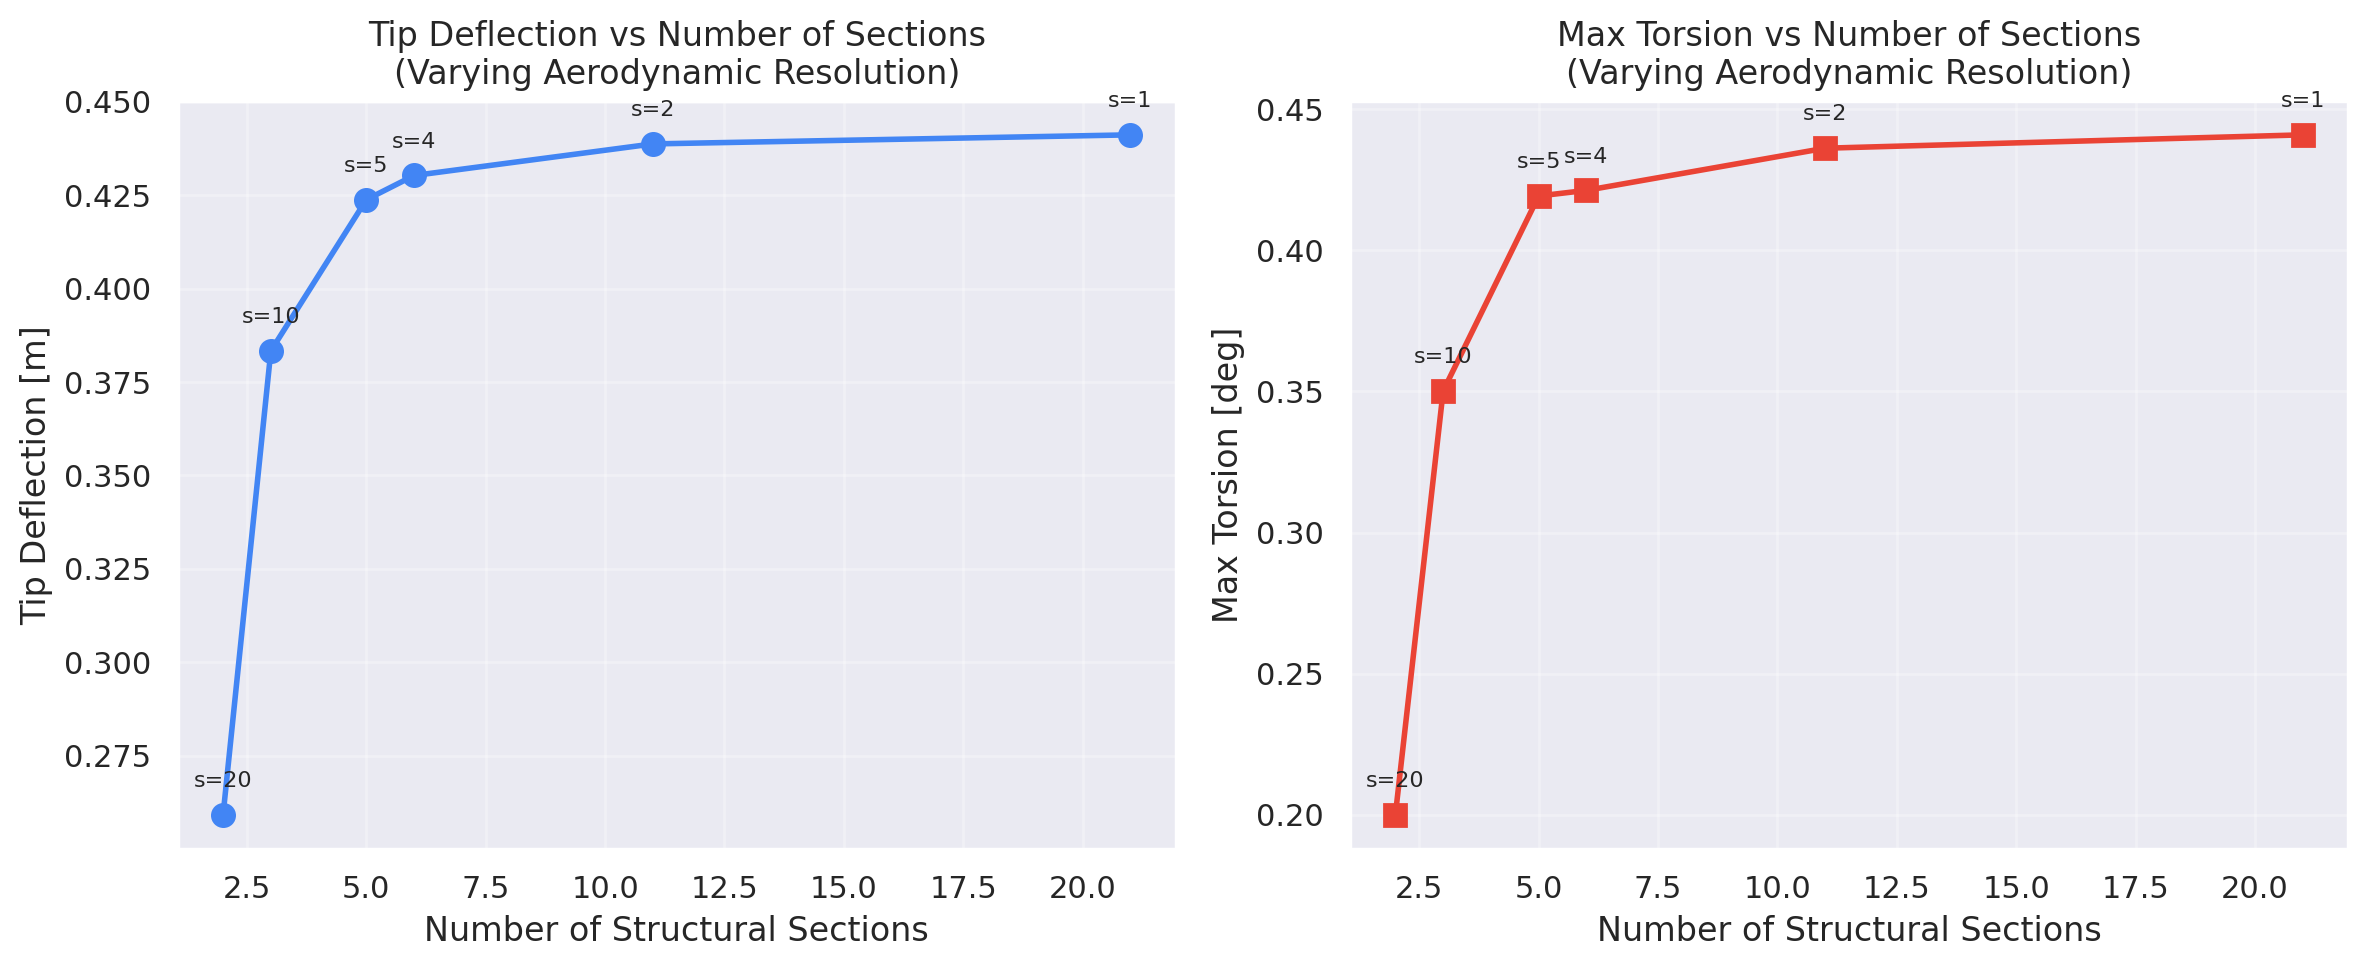


Completed 6 test cases
Sections   Spanwise   Total Panels    Tip Defl [m]    Max Torsion [deg]
------------------------------------------------------------
2          20         100             0.259221        0.200119
3          10         100             0.383338        0.350201
5          5          100             0.423815        0.419255
6          4          100             0.430282        0.421253
11         2          100             0.438735        0.436184
21         1          100             0.441162        0.440917


In [19]:
# Fixed chordwise resolution
chordwise_panels_per_section = 5

# Specific test cases: (n_sections, spanwise_resolution)
test_cases = [
    (2, 20),
    (3, 10),
    (5, 5),
    (6, 4),
    (11, 2),
    (21, 1),
]

structural_sweep_results = run_structural_resolution_sweep(
    span=span,
    chord_fun=chord_fun,
    twist_fun=twist_fun,
    EI_func=EI_func,
    GJ_func=GJ_func,
    test_cases=test_cases,
    chordwise_panels_per_section=chordwise_panels_per_section,
    bending_model="moment",
)

num_sections_list = [r["n_sections"] for r in structural_sweep_results]
spanwise_res_list = [r["spanwise_resolution"] for r in structural_sweep_results]
tip_deflection = [r["tip_deflection"] for r in structural_sweep_results]
max_torsion = [r["max_torsion"] for r in structural_sweep_results]

# Plot 2D results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(num_sections_list, tip_deflection, 'o-', linewidth=2, markersize=8)
ax1.set_xlabel('Number of Structural Sections')
ax1.set_ylabel('Tip Deflection [m]')
ax1.set_title('Tip Deflection vs Number of Sections\n(Varying Aerodynamic Resolution)')
ax1.grid(True, alpha=0.3)
for x, y, s in zip(num_sections_list, tip_deflection, spanwise_res_list):
    ax1.annotate(f's={s}', (x, y), textcoords="offset points", xytext=(0, 10), ha='center', fontsize=8)

ax2.plot(num_sections_list, max_torsion, 's-', linewidth=2, markersize=8, color='C1')
ax2.set_xlabel('Number of Structural Sections')
ax2.set_ylabel('Max Torsion [deg]')
ax2.set_title('Max Torsion vs Number of Sections\n(Varying Aerodynamic Resolution)')
ax2.grid(True, alpha=0.3)
for x, y, s in zip(num_sections_list, max_torsion, spanwise_res_list):
    ax2.annotate(f's={s}', (x, y), textcoords="offset points", xytext=(0, 10), ha='center', fontsize=8)

plt.tight_layout()
plt.show()

print(f"\n{'=' * 60}")
print(f"Completed {len(num_sections_list)} test cases")
print(f"{'=' * 60}")
print(f"{'Sections':<10} {'Spanwise':<10} {'Total Panels':<15} {'Tip Defl [m]':<15} {'Max Torsion [deg]'}")
print(f"{'-' * 60}")
for row in structural_sweep_results:
    print(
        f"{row['n_sections']:<10} {row['spanwise_resolution']:<10} {row['total_panels']:<15} "
        f"{row['tip_deflection']:<15.6f} {row['max_torsion']:.6f}"
    )

### Alternative visualization
The following section reproduces and visualizes the same convergence behavior with a cleaner side-by-side plotting style.

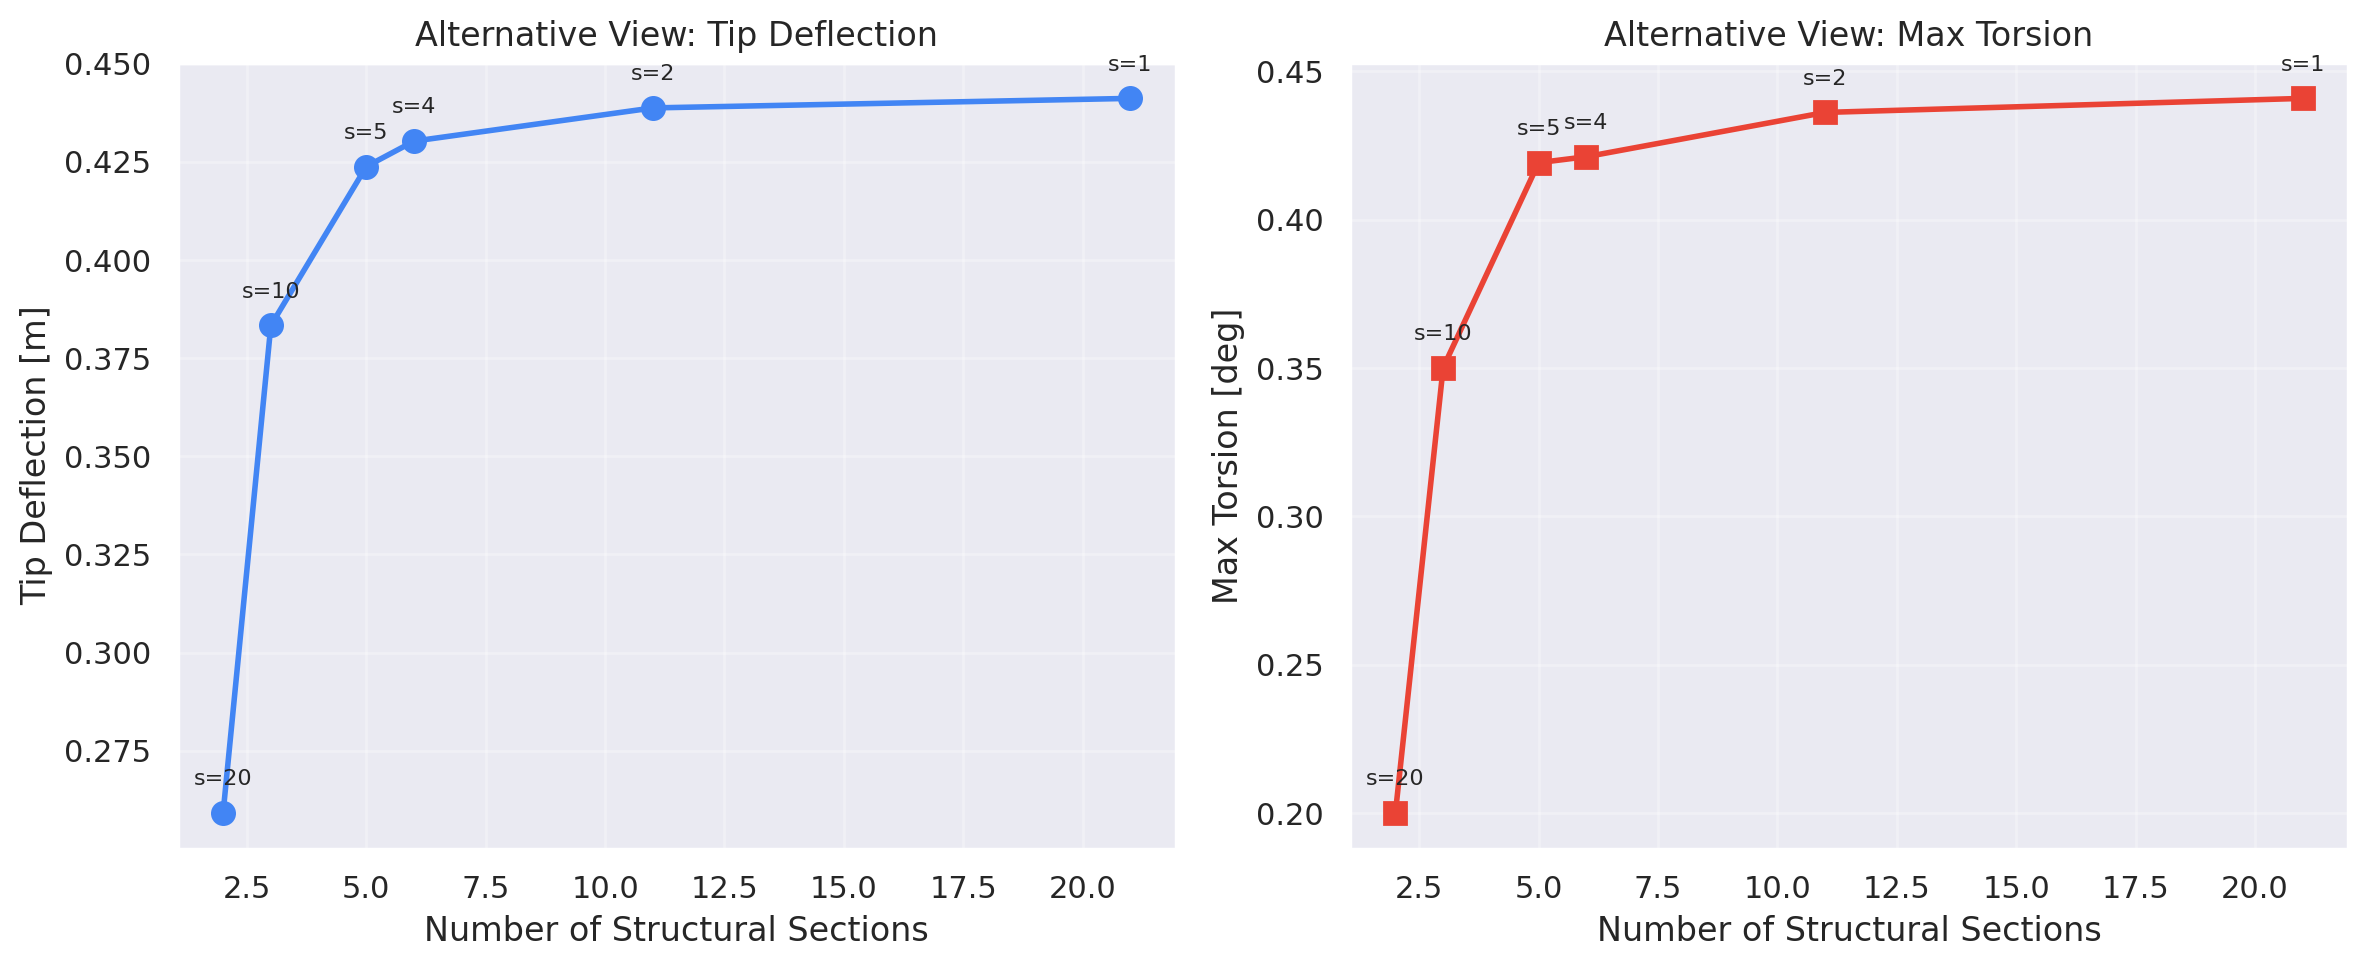

In [20]:
# Alternative plotting style using the already computed structural sweep results.
if 'structural_sweep_results' not in globals():
    # Fallback if this cell is run in isolation.
    chordwise_panels_per_section = 5
    test_cases = [
        (2, 20),
        (3, 10),
        (5, 5),
        (6, 4),
        (11, 2),
        (21, 1),
    ]
    structural_sweep_results = run_structural_resolution_sweep(
        span=span,
        chord_fun=chord_fun,
        twist_fun=twist_fun,
        EI_func=EI_func,
        GJ_func=GJ_func,
        test_cases=test_cases,
        chordwise_panels_per_section=chordwise_panels_per_section,
        bending_model="moment",
    )

num_sections_alt = np.array([r["n_sections"] for r in structural_sweep_results])
spanwise_alt = np.array([r["spanwise_resolution"] for r in structural_sweep_results])
tip_deflection_alt = np.array([r["tip_deflection"] for r in structural_sweep_results])
max_torsion_alt = np.array([r["max_torsion"] for r in structural_sweep_results])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(num_sections_alt, tip_deflection_alt, marker='o', linestyle='-', linewidth=2, markersize=8)
ax1.set_xlabel('Number of Structural Sections')
ax1.set_ylabel('Tip Deflection [m]')
ax1.set_title('Alternative View: Tip Deflection')
ax1.grid(True, alpha=0.3)
for x, y, s in zip(num_sections_alt, tip_deflection_alt, spanwise_alt):
    ax1.annotate(f's={s}', (x, y), textcoords='offset points', xytext=(0, 10), ha='center', fontsize=8)

ax2.plot(num_sections_alt, max_torsion_alt, marker='s', linestyle='-', linewidth=2, markersize=8, color='C1')
ax2.set_xlabel('Number of Structural Sections')
ax2.set_ylabel('Max Torsion [deg]')
ax2.set_title('Alternative View: Max Torsion')
ax2.grid(True, alpha=0.3)
for x, y, s in zip(num_sections_alt, max_torsion_alt, spanwise_alt):
    ax2.annotate(f's={s}', (x, y), textcoords='offset points', xytext=(0, 10), ha='center', fontsize=8)

plt.tight_layout()
plt.show()